# Homework Heuristic Search

First thing first let's import some modules

In [4]:
from domain.agent import Agent
from maze_generators import randomized, backtracking
from heuristics import manhattan, euclidean
import matplotlib.pyplot as plt
from screen import animation
from IPython.display import Video
import os
import cProfile
import copy
import pstats

create some constants that are used in our notebook

In [5]:
MAZE_HEIGHT = 10
MAZE_WIDTH = 10

MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME = "MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME"
EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME = "EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME"
MANHATTAN_DISTANCE_HEURISTIC_A_STAR_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME = "MANHATTAN_DISTANCE_HEURISTIC_A_STAR_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME"
EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME = "EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME"
DFS_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME = "DFS_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME"

MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME = "MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME"
EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME = "EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME"
MANHATTAN_DISTANCE_HEURISTIC_A_STAR_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME = "MANHATTAN_DISTANCE_HEURISTIC_A_STAR_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME"
EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME = "EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME"
DFS_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME = "DFS_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME"
WALL_FOLLOWING_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME = "WALL_FOLLOWING_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME"

VIDEO_EXTENSION = ".mp4"

VIDEO_FILE_NAMES = {
    MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME: "manhattan_distance_heuristic_best_first_randomly_generated_maze" + VIDEO_EXTENSION,
    EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME: "euclidean_distance_heuristic_best_first_randomly_generated_maze" + VIDEO_EXTENSION,
    MANHATTAN_DISTANCE_HEURISTIC_A_STAR_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME: "manhattan_distance_heuristic_a_star_randomly_generated_maze" + VIDEO_EXTENSION,
    EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME: "euclidean_distance_heuristic_a_star_randomly_generated_maze" + VIDEO_EXTENSION,
    DFS_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME: "dfs_randomly_generated_maze" + VIDEO_EXTENSION,
    MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME: "manhattan_distance_heuristic_best_first_backtracking_generated_maze" + VIDEO_EXTENSION,
    MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME: "manhattan_distance_heuristic_best_first_backtracking_generated_maze" + VIDEO_EXTENSION,
    EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME: "euclidean_distance_heuristic_best_first_backtracking_generated_maze" + VIDEO_EXTENSION,
    MANHATTAN_DISTANCE_HEURISTIC_A_STAR_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME: "manhattan_distance_heuristic_a_star_backtracking_generated_maze" + VIDEO_EXTENSION,
    EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME: "euclidean_distance_heuristic_a_star_backtracking_generated_maze" + VIDEO_EXTENSION,
    DFS_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME: "dfs_backtracking_generated_maze" + VIDEO_EXTENSION,
    WALL_FOLLOWING_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME: "wall_following_backtracking_generated_maze" + VIDEO_EXTENSION,
}

ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY = "backtracking_generated_maze"
ALGORITHM_COMPUTATION_DICTIONARY_RANDOMLY_GENERATED_MAZE_KEY = "randomly_generated_maze"

ALGORITHM_COMPUTATION_DICTIONARY_MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_KEY = "manhattan_distance_heuristic_best_first_algorithm"
ALGORITHM_COMPUTATION_DICTIONARY_EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_KEY = "euclidean_distance_heuristic_best_first_algorithm"
ALGORITHM_COMPUTATION_DICTIONARY_MANHATTAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_KEY = "manhattan_distance_heuristic_a_star_algorithm"
ALGORITHM_COMPUTATION_DICTIONARY_EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_KEY = "euclidean_distance_heuristic_a_star_algorithm"
ALGORITHM_COMPUTATION_DICTIONARY_DFS_ALGORITHM_KEY = "dfs_algorithm"
ALGORITHM_COMPUTATION_DICTIONARY_WALL_FOLLOWING_ALGORITHM_KEY = "wall_following_algorithm"

ALGORITHM_COMPUTATION_DICTIONARY_PATH_LENGTH_KEY = "path_length"
ALGORITHM_COMPUTATION_DICTIONARY_AGENT_STATES_NUMBER_KEY = "agent_states_number"
ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_FUNCTION_CALLS_NUMBER_KEY = "total_function_calls_number"
ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_TIME_NUMBER_KEY = "total_time_number"

algorithm_computation_stats = {
    ALGORITHM_COMPUTATION_DICTIONARY_RANDOMLY_GENERATED_MAZE_KEY: {
        ALGORITHM_COMPUTATION_DICTIONARY_MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_KEY: {
            ALGORITHM_COMPUTATION_DICTIONARY_PATH_LENGTH_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_AGENT_STATES_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_FUNCTION_CALLS_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_TIME_NUMBER_KEY: None
        },
        ALGORITHM_COMPUTATION_DICTIONARY_EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_KEY: {
            ALGORITHM_COMPUTATION_DICTIONARY_PATH_LENGTH_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_AGENT_STATES_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_FUNCTION_CALLS_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_TIME_NUMBER_KEY: None
        },
        ALGORITHM_COMPUTATION_DICTIONARY_MANHATTAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_KEY: {
            ALGORITHM_COMPUTATION_DICTIONARY_PATH_LENGTH_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_AGENT_STATES_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_FUNCTION_CALLS_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_TIME_NUMBER_KEY: None
        },
        ALGORITHM_COMPUTATION_DICTIONARY_EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_KEY: {
            ALGORITHM_COMPUTATION_DICTIONARY_PATH_LENGTH_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_AGENT_STATES_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_FUNCTION_CALLS_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_TIME_NUMBER_KEY: None
        },
        ALGORITHM_COMPUTATION_DICTIONARY_DFS_ALGORITHM_KEY: {
            ALGORITHM_COMPUTATION_DICTIONARY_PATH_LENGTH_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_AGENT_STATES_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_FUNCTION_CALLS_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_TIME_NUMBER_KEY: None
        }
    },
    ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY: {
        ALGORITHM_COMPUTATION_DICTIONARY_MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_KEY: {
            ALGORITHM_COMPUTATION_DICTIONARY_PATH_LENGTH_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_AGENT_STATES_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_FUNCTION_CALLS_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_TIME_NUMBER_KEY: None
        },
        ALGORITHM_COMPUTATION_DICTIONARY_EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_KEY: {
            ALGORITHM_COMPUTATION_DICTIONARY_PATH_LENGTH_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_AGENT_STATES_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_FUNCTION_CALLS_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_TIME_NUMBER_KEY: None
        },
        ALGORITHM_COMPUTATION_DICTIONARY_MANHATTAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_KEY: {
            ALGORITHM_COMPUTATION_DICTIONARY_PATH_LENGTH_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_AGENT_STATES_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_FUNCTION_CALLS_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_TIME_NUMBER_KEY: None
        },
        ALGORITHM_COMPUTATION_DICTIONARY_EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_KEY: {
            ALGORITHM_COMPUTATION_DICTIONARY_PATH_LENGTH_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_AGENT_STATES_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_FUNCTION_CALLS_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_TIME_NUMBER_KEY: None
        },
        ALGORITHM_COMPUTATION_DICTIONARY_DFS_ALGORITHM_KEY: {
            ALGORITHM_COMPUTATION_DICTIONARY_PATH_LENGTH_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_AGENT_STATES_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_FUNCTION_CALLS_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_TIME_NUMBER_KEY: None
        },
        ALGORITHM_COMPUTATION_DICTIONARY_WALL_FOLLOWING_ALGORITHM_KEY: {
            ALGORITHM_COMPUTATION_DICTIONARY_PATH_LENGTH_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_AGENT_STATES_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_FUNCTION_CALLS_NUMBER_KEY: None,
            ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_TIME_NUMBER_KEY: None
        }
    }
}

and remove some old files

In [6]:
for video_name in VIDEO_FILE_NAMES:
    video = VIDEO_FILE_NAMES[video_name]
    if os.path.exists(video):
      os.remove(video)
      print(f"File '{video}' deleted successfully.")
    else:
      print(f"File '{video}' does not exist.")

File 'manhattan_distance_heuristic_best_first_randomly_generated_maze.mp4' deleted successfully.
File 'euclidean_distance_heuristic_best_first_randomly_generated_maze.mp4' deleted successfully.
File 'manhattan_distance_heuristic_a_star_randomly_generated_maze.mp4' deleted successfully.
File 'euclidean_distance_heuristic_a_star_randomly_generated_maze.mp4' deleted successfully.
File 'dfs_randomly_generated_maze.mp4' deleted successfully.
File 'manhattan_distance_heuristic_best_first_backtracking_generated_maze.mp4' deleted successfully.
File 'euclidean_distance_heuristic_best_first_backtracking_generated_maze.mp4' deleted successfully.
File 'manhattan_distance_heuristic_a_star_backtracking_generated_maze.mp4' deleted successfully.
File 'euclidean_distance_heuristic_a_star_backtracking_generated_maze.mp4' deleted successfully.
File 'dfs_backtracking_generated_maze.mp4' deleted successfully.
File 'wall_following_backtracking_generated_maze.mp4' deleted successfully.


## Randomly Generated Maze

Now, how can we solve a maze if we don't even have one to work with in the first place?

Let's generate a maze with random obstacles!

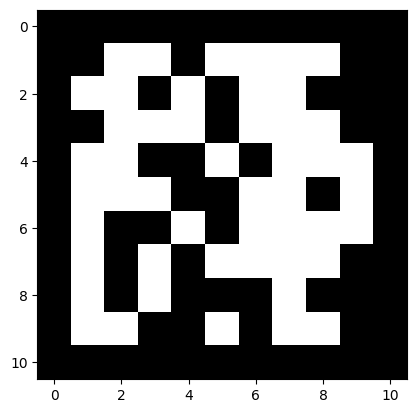

In [7]:
randomly_generated_maze = randomized.create_maze(MAZE_HEIGHT, MAZE_WIDTH)
plt.imshow(randomly_generated_maze.maze, cmap='gray')
plt.show()

and put an agent inside it.

In [8]:
agent = Agent(randomly_generated_maze)

We then create a function that processes a generic maze runner function that we will pass

In [9]:
def process_maze_runner_function(maze_runner_function, heuristic, video_file_name_key, algorithm_computation_dictionary_maze_type, algorithm_computation_dictionary_function_key):
    with cProfile.Profile() as pr:
        if heuristic is not None:
            maze_path = maze_runner_function(heuristic)
        else:
            maze_path = maze_runner_function()
    
    stats = pstats.Stats(pr)

    # Get the total number of function calls
    total_function_calls = stats.total_calls

    # Get the total time in seconds
    total_time = stats.total_tt

    print(f"Path length: {len(maze_path)} cells")
    print(f"Number of agent states: {len(agent.states)} states")

    stats.print_stats()

    # Put stats inside the algorithm computation stats dictionary
    algorithm_computation_stats[algorithm_computation_dictionary_maze_type][algorithm_computation_dictionary_function_key][ALGORITHM_COMPUTATION_DICTIONARY_PATH_LENGTH_KEY] = len(maze_path)
    algorithm_computation_stats[algorithm_computation_dictionary_maze_type][algorithm_computation_dictionary_function_key][ALGORITHM_COMPUTATION_DICTIONARY_AGENT_STATES_NUMBER_KEY] = len(agent.states)
    algorithm_computation_stats[algorithm_computation_dictionary_maze_type][algorithm_computation_dictionary_function_key][ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_FUNCTION_CALLS_NUMBER_KEY] = total_function_calls
    algorithm_computation_stats[algorithm_computation_dictionary_maze_type][algorithm_computation_dictionary_function_key][ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_TIME_NUMBER_KEY] = total_time
    
    # Animate the maze runner
    animation.animate(agent.maze, maze_path, VIDEO_FILE_NAMES[video_file_name_key])

Now that everything is set up we can start solving this maze with different algorithms.

In every maze solution that will follow, start position is **(0,0)** and goal is **(n,n)**

### Best First Algorithm

The first algorithm to test will be the best first algorithm

#### Manhattan Distance Heuristic

Let's test the best first algorithm with Manhattan distance heuristic on the previously generated maze

Path length: 35 cells
Number of agent states: 17 states
         7386 function calls (6349 primitive calls) in 0.002 seconds

   Random listing order was used

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      216    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\types.py:171(__get__)
      216    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\enum.py:792(value)
        3    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:228(__init__)
       36    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:256(__enter__)
       36    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:259(__exit__)
       36    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\thr

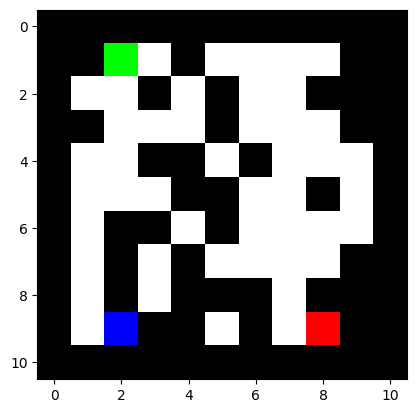

In [10]:
process_maze_runner_function(agent.best_first, manhattan.manhattan_distance_heuristic, MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME, ALGORITHM_COMPUTATION_DICTIONARY_RANDOMLY_GENERATED_MAZE_KEY, ALGORITHM_COMPUTATION_DICTIONARY_MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_KEY)
Video(VIDEO_FILE_NAMES[MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME])

#### Euclidean Distance Heuristic

Let's test the best first algorithm with Euclidean distance heuristic on the previously generated maze

Path length: 35 cells
Number of agent states: 17 states
         7331 function calls (6294 primitive calls) in 0.002 seconds

   Random listing order was used

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      216    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\types.py:171(__get__)
      216    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\enum.py:792(value)
        3    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:228(__init__)
       36    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:256(__enter__)
       36    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:259(__exit__)
       36    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\thr

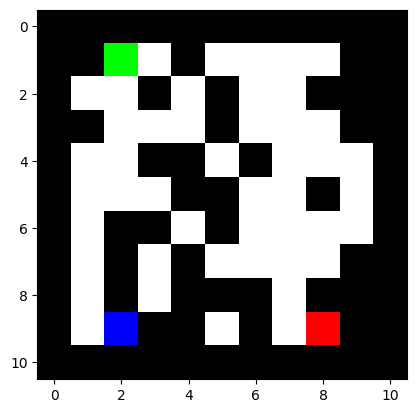

In [11]:
process_maze_runner_function(agent.best_first, euclidean.euclidean_distance_heuristic, EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME, ALGORITHM_COMPUTATION_DICTIONARY_RANDOMLY_GENERATED_MAZE_KEY, ALGORITHM_COMPUTATION_DICTIONARY_EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_KEY)
Video(VIDEO_FILE_NAMES[EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME])

### A* Algorithm

Having seen the Best First algorithm we now focus on the A* algorithm in both heuristics

#### Manhattan Distance Heuristic

Let's test the A* algorithm with the Manhattan distance heuristic

Path length: 35 cells
Number of agent states: 17 states
         7394 function calls (6357 primitive calls) in 0.003 seconds

   Random listing order was used

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      216    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\types.py:171(__get__)
      216    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\enum.py:792(value)
        3    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:228(__init__)
       36    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:256(__enter__)
       36    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:259(__exit__)
       36    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\thr

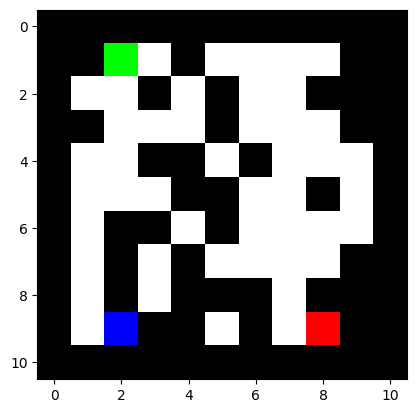

In [12]:
process_maze_runner_function(agent.a_star, manhattan.manhattan_distance_heuristic, MANHATTAN_DISTANCE_HEURISTIC_A_STAR_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME, ALGORITHM_COMPUTATION_DICTIONARY_RANDOMLY_GENERATED_MAZE_KEY, ALGORITHM_COMPUTATION_DICTIONARY_MANHATTAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_KEY)
Video(VIDEO_FILE_NAMES[MANHATTAN_DISTANCE_HEURISTIC_A_STAR_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME])

#### Euclidean Distance Heuristic

Let's test the A* algorithm with the Euclidean distance heuristic

Path length: 43 cells
Number of agent states: 17 states
         7385 function calls (6348 primitive calls) in 0.003 seconds

   Random listing order was used

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      216    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\types.py:171(__get__)
      216    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\enum.py:792(value)
        3    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:228(__init__)
       36    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:256(__enter__)
       36    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:259(__exit__)
       36    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\thr

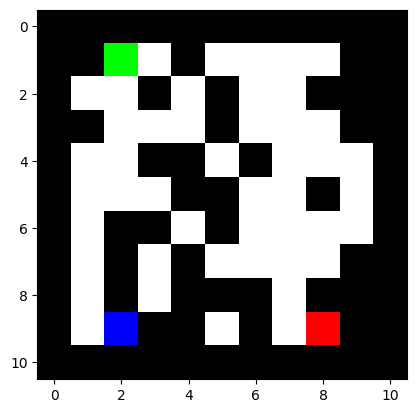

In [13]:
process_maze_runner_function(agent.a_star, euclidean.euclidean_distance_heuristic, EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME, ALGORITHM_COMPUTATION_DICTIONARY_RANDOMLY_GENERATED_MAZE_KEY, ALGORITHM_COMPUTATION_DICTIONARY_EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_KEY)
Video(VIDEO_FILE_NAMES[EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME])

### DFS Algorithm

Another algorithm worth of mentioning is the Depth First Search (or DFS) algorithm. Let's test how it performs as a maze runner in this kind of maze.

Path length: 36 cells
Number of agent states: 17 states
         6652 function calls (5615 primitive calls) in 0.002 seconds

   Random listing order was used

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      166    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\types.py:171(__get__)
      166    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\enum.py:792(value)
  1038/18    0.001    0.000    0.002    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\copy.py:128(deepcopy)
      680    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\copy.py:182(_deepcopy_atomic)
      340    0.000    0.000    0.001    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\copy.py:210(<listcomp>)
      340    0.000    0.000    0.001    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\copy.py:2

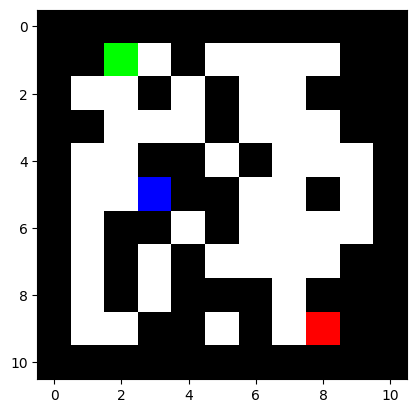

In [14]:
process_maze_runner_function(agent.dfs, None, DFS_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME, ALGORITHM_COMPUTATION_DICTIONARY_RANDOMLY_GENERATED_MAZE_KEY, ALGORITHM_COMPUTATION_DICTIONARY_DFS_ALGORITHM_KEY)
Video(VIDEO_FILE_NAMES[DFS_RANDOMLY_GENERATED_MAZE_VIDEO_FILE_NAME])

**Note that as this algorithm does not use an heuristic, it is much slower to find a path than the other two!**

## Backtracking Generated Maze

Until now we have seen algorithms working on a maze generated with random obstacles, but what about a "true" maze with paths generated by a backtracking algorithm like the following one?

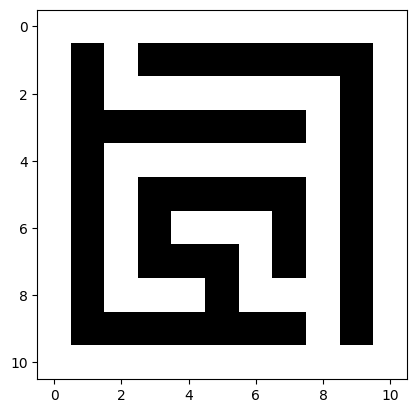

In [15]:
backtracking_generated_maze = backtracking.create_maze(MAZE_HEIGHT, MAZE_WIDTH)
plt.imshow(backtracking_generated_maze.maze, cmap='gray')
plt.show()

Let's test the algorithms again on this maze! Remember that in every maze solution that will follow, start position is **(0,0)** and goal is **(n,n)**

First we place the agent on the newly generated maze

In [16]:
agent.maze = backtracking_generated_maze

### Best First Algorithm

The first algorithm to test will be the best first algorithm

#### Manhattan Distance Heuristic

Let's test the best first algorithm with Manhattan distance heuristic on the previously generated maze

Path length: 15 cells
Number of agent states: 16 states
         1628 function calls (1518 primitive calls) in 0.001 seconds

   Random listing order was used

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      172    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\types.py:171(__get__)
      172    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\enum.py:792(value)
        3    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:228(__init__)
       32    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:256(__enter__)
       32    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:259(__exit__)
       32    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\thr

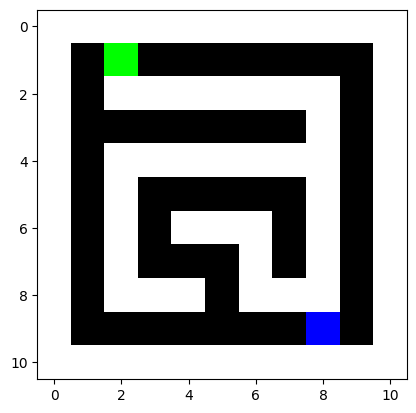

In [17]:
process_maze_runner_function(agent.best_first, manhattan.manhattan_distance_heuristic, MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME, ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY, ALGORITHM_COMPUTATION_DICTIONARY_MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_KEY)
Video(VIDEO_FILE_NAMES[MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME])

#### Euclidean Distance Heuristic

Let's test the best first algorithm with Euclidean distance heuristic on the previously generated maze

Path length: 15 cells
Number of agent states: 16 states
         1581 function calls (1471 primitive calls) in 0.001 seconds

   Random listing order was used

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      172    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\types.py:171(__get__)
      172    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\enum.py:792(value)
        3    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:228(__init__)
       32    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:256(__enter__)
       32    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:259(__exit__)
       32    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\thr

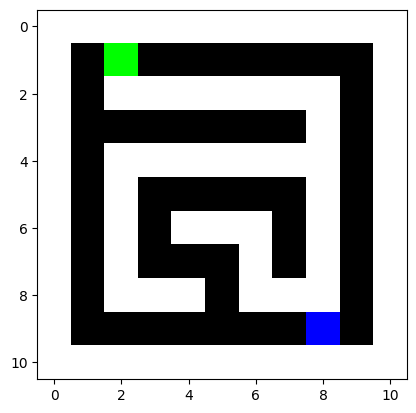

In [18]:
process_maze_runner_function(agent.best_first, euclidean.euclidean_distance_heuristic, EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME, ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY, ALGORITHM_COMPUTATION_DICTIONARY_EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_KEY)
Video(VIDEO_FILE_NAMES[EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME])

### A* Algorithm

Having seen the Best First algorithm we now focus on the A* algorithm in both heuristics

#### Manhattan Distance Heuristic

Let's test the A* algorithm with the Manhattan distance heuristic

Path length: 15 cells
Number of agent states: 16 states
         1636 function calls (1526 primitive calls) in 0.001 seconds

   Random listing order was used

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      172    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\types.py:171(__get__)
      172    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\enum.py:792(value)
        3    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:228(__init__)
       32    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:256(__enter__)
       32    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:259(__exit__)
       32    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\thr

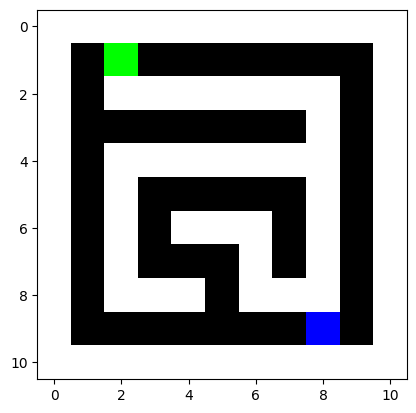

In [19]:
process_maze_runner_function(agent.a_star, manhattan.manhattan_distance_heuristic, MANHATTAN_DISTANCE_HEURISTIC_A_STAR_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME, ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY, ALGORITHM_COMPUTATION_DICTIONARY_MANHATTAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_KEY)
Video(VIDEO_FILE_NAMES[MANHATTAN_DISTANCE_HEURISTIC_A_STAR_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME])

#### Euclidean Distance Heuristic

Let's test the A* algorithm with the Euclidean distance heuristic

Path length: 15 cells
Number of agent states: 16 states
         1588 function calls (1478 primitive calls) in 0.001 seconds

   Random listing order was used

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      172    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\types.py:171(__get__)
      172    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\enum.py:792(value)
        3    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:228(__init__)
       32    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:256(__enter__)
       32    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\threading.py:259(__exit__)
       32    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\thr

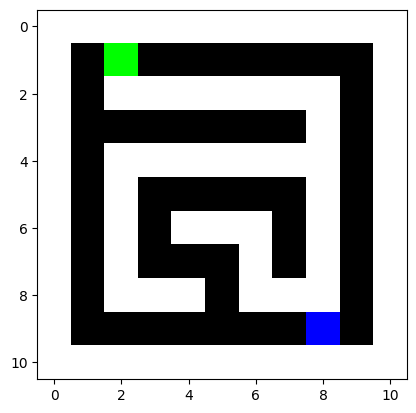

In [20]:
process_maze_runner_function(agent.a_star, euclidean.euclidean_distance_heuristic, EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME, ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY, ALGORITHM_COMPUTATION_DICTIONARY_EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_KEY)
Video(VIDEO_FILE_NAMES[EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME])

### DFS Algorithm

Let's now focus on the DFS algorithm and see how it performs in this type of maze

Path length: 15 cells
Number of agent states: 32 states
         1992 function calls (1786 primitive calls) in 0.001 seconds

   Random listing order was used

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      276    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\types.py:171(__get__)
      276    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\enum.py:792(value)
    193/1    0.000    0.000    0.001    0.001 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\copy.py:128(deepcopy)
      128    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\copy.py:182(_deepcopy_atomic)
       64    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\copy.py:210(<listcomp>)
       64    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\copy.py:2

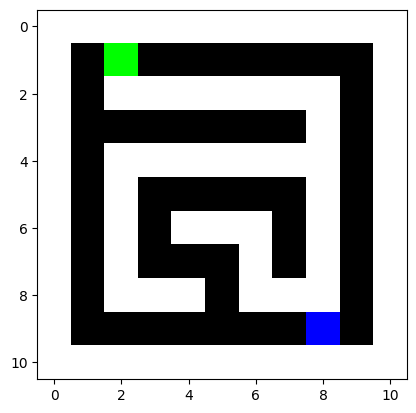

In [21]:
process_maze_runner_function(agent.dfs, None, DFS_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME, ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY, ALGORITHM_COMPUTATION_DICTIONARY_DFS_ALGORITHM_KEY)
Video(VIDEO_FILE_NAMES[DFS_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME])

### Wall Following Algorithm

Another algorithm that can be applied on this kind of maze is the **Wall Following Algorithm**, which tries to find an exit while always following the left/right wall.

Here is an implementation that always follows the left wall.

Path length: 15 cells
Number of agent states: 14 states
         795 function calls (711 primitive calls) in 0.000 seconds

   Random listing order was used

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      113    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\types.py:171(__get__)
       71    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\enum.py:787(name)
       42    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\enum.py:792(value)
     85/1    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\copy.py:128(deepcopy)
       56    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\copy.py:182(_deepcopy_atomic)
       28    0.000    0.000    0.000    0.000 C:\Users\Calogero\AppData\Local\Programs\Python\Python39\lib\copy.py:210(<list

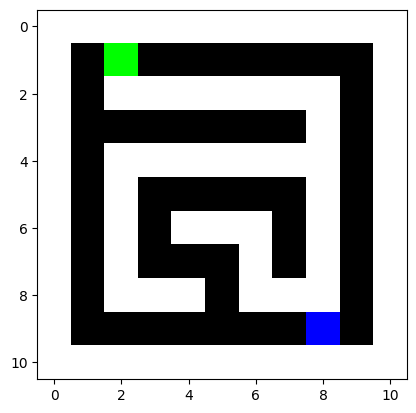

In [22]:
process_maze_runner_function(agent.wall_follower, None, WALL_FOLLOWING_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME, ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY, ALGORITHM_COMPUTATION_DICTIONARY_WALL_FOLLOWING_ALGORITHM_KEY)
Video(VIDEO_FILE_NAMES[WALL_FOLLOWING_BACKTRACKING_GENERATED_MAZE_VIDEO_FILE_NAME])

## Analysis

Let's draw some graph that help us understand the shown algorithm a bit better.

The below graph shows use the different execution time of each algorithm in the randomly generated maze

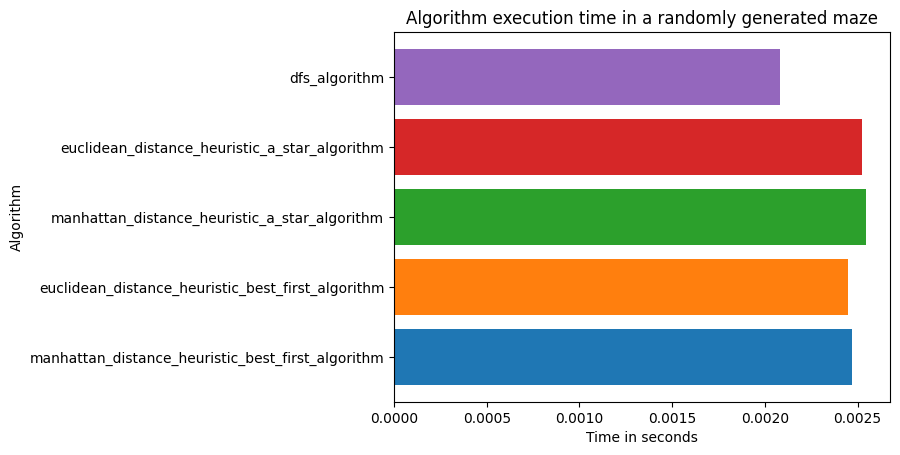

In [23]:
# Create plot
figure, axes = plt.subplots()

for key in algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_RANDOMLY_GENERATED_MAZE_KEY]:
    current_algorithm = algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_RANDOMLY_GENERATED_MAZE_KEY][key]
    # draw time bars
    axes.barh(key, current_algorithm[ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_TIME_NUMBER_KEY])

plt.xlabel('Time in seconds')
plt.ylabel('Algorithm')
plt.title('Algorithm execution time in a randomly generated maze')

# Show graph
plt.show()

while this one in the backtracking generated one

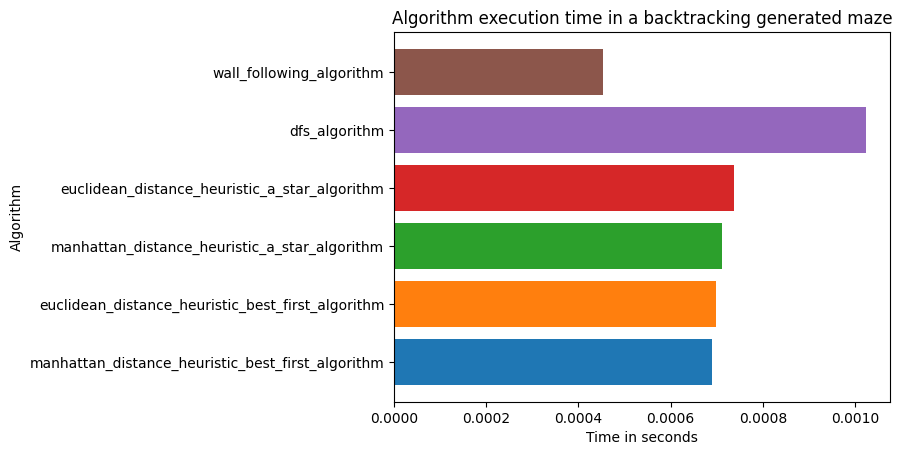

In [24]:
# Create plot
figure, axes = plt.subplots()

for key in algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY]:
    current_algorithm = algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY][key]
    # draw time bars
    axes.barh(key, current_algorithm[ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_TIME_NUMBER_KEY])

plt.xlabel('Time in seconds')
plt.ylabel('Algorithm')
plt.title('Algorithm execution time in a backtracking generated maze')

# Show graph
plt.show()

Let's now compare path lengths

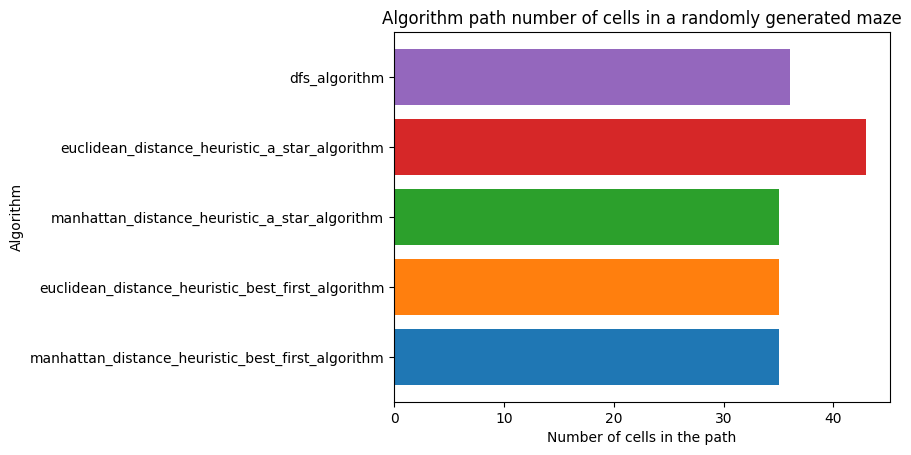

In [25]:
# Create plot
figure, axes = plt.subplots()

for key in algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_RANDOMLY_GENERATED_MAZE_KEY]:
    current_algorithm = algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_RANDOMLY_GENERATED_MAZE_KEY][key]
    # draw time bars
    axes.barh(key, current_algorithm[ALGORITHM_COMPUTATION_DICTIONARY_PATH_LENGTH_KEY])

plt.xlabel('Number of cells in the path')
plt.ylabel('Algorithm')
plt.title('Algorithm path number of cells in a randomly generated maze')

# Show graph
plt.show()

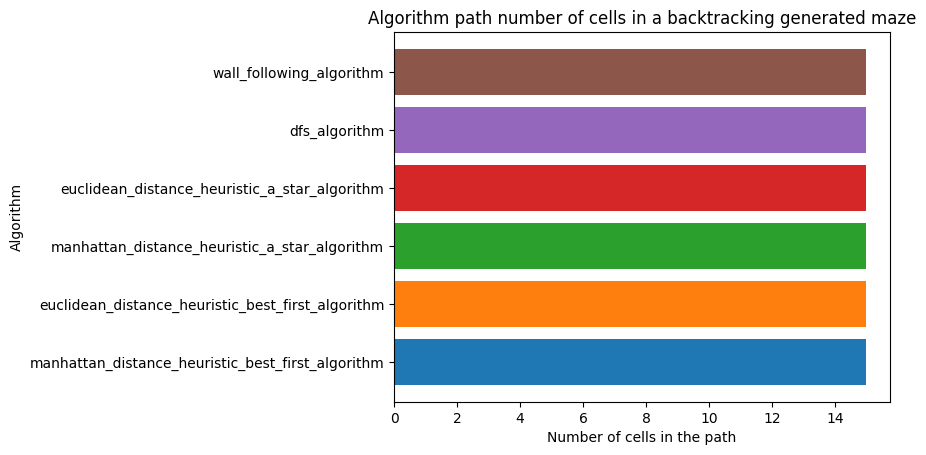

In [26]:
# Create plot
figure, axes = plt.subplots()

for key in algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY]:
    current_algorithm = algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY][key]
    # draw time bars
    axes.barh(key, current_algorithm[ALGORITHM_COMPUTATION_DICTIONARY_PATH_LENGTH_KEY])

plt.xlabel('Number of cells in the path')
plt.ylabel('Algorithm')
plt.title('Algorithm path number of cells in a backtracking generated maze')

# Show graph
plt.show()

number of agent states

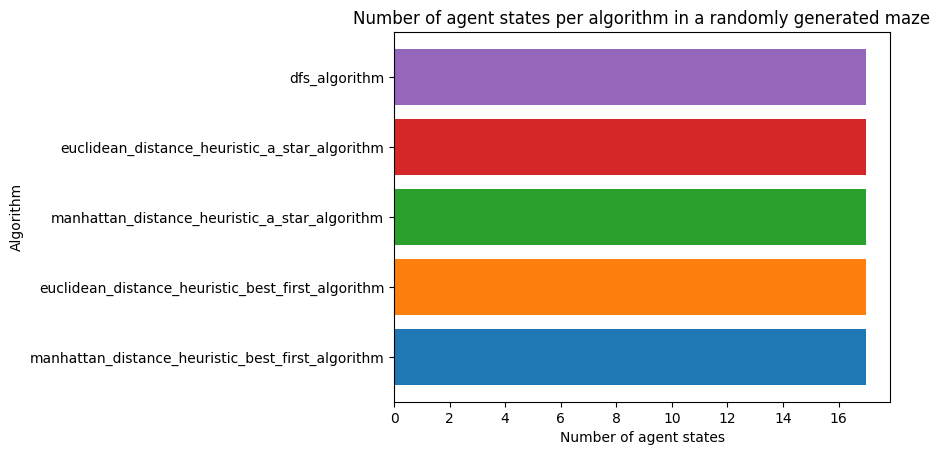

In [27]:
# Create plot
figure, axes = plt.subplots()

for key in algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_RANDOMLY_GENERATED_MAZE_KEY]:
    current_algorithm = algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_RANDOMLY_GENERATED_MAZE_KEY][key]
    # draw time bars
    axes.barh(key, current_algorithm[ALGORITHM_COMPUTATION_DICTIONARY_AGENT_STATES_NUMBER_KEY])

plt.xlabel('Number of agent states')
plt.ylabel('Algorithm')
plt.title('Number of agent states per algorithm in a randomly generated maze')

# Show graph
plt.show()

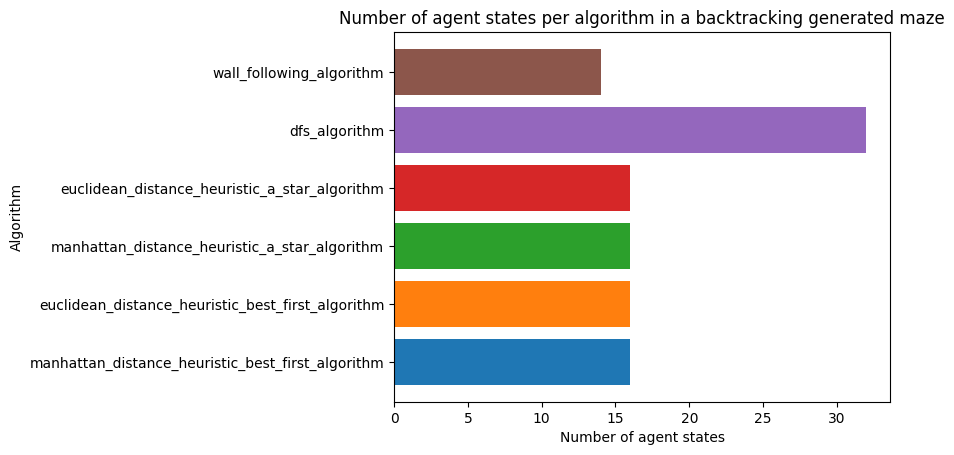

In [28]:
# Create plot
figure, axes = plt.subplots()

for key in algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY]:
    current_algorithm = algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY][key]
    # draw time bars
    axes.barh(key, current_algorithm[ALGORITHM_COMPUTATION_DICTIONARY_AGENT_STATES_NUMBER_KEY])

plt.xlabel('Number of agent states')
plt.ylabel('Algorithm')
plt.title('Number of agent states per algorithm in a backtracking generated maze')

# Show graph
plt.show()

and last but not at least, number of total function calls

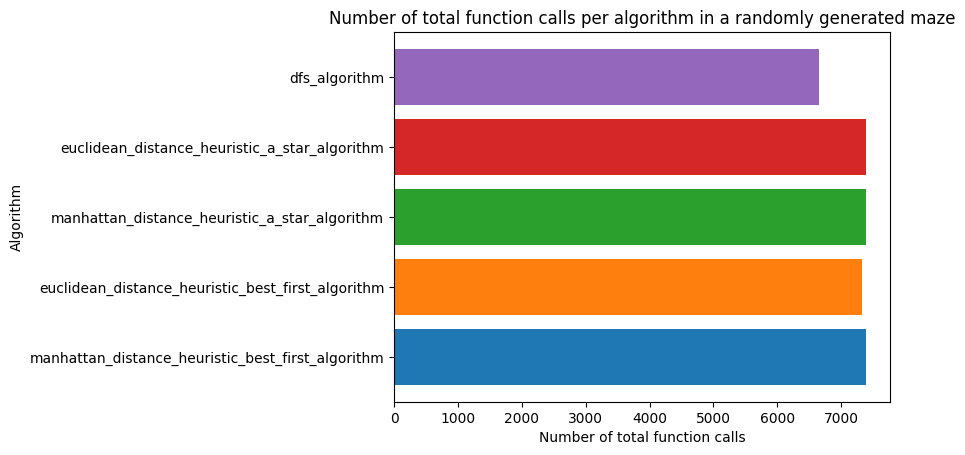

In [29]:
# Create plot
figure, axes = plt.subplots()

for key in algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_RANDOMLY_GENERATED_MAZE_KEY]:
    current_algorithm = algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_RANDOMLY_GENERATED_MAZE_KEY][key]
    # draw time bars
    axes.barh(key, current_algorithm[ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_FUNCTION_CALLS_NUMBER_KEY])

plt.xlabel('Number of total function calls')
plt.ylabel('Algorithm')
plt.title('Number of total function calls per algorithm in a randomly generated maze')

# Show graph
plt.show()

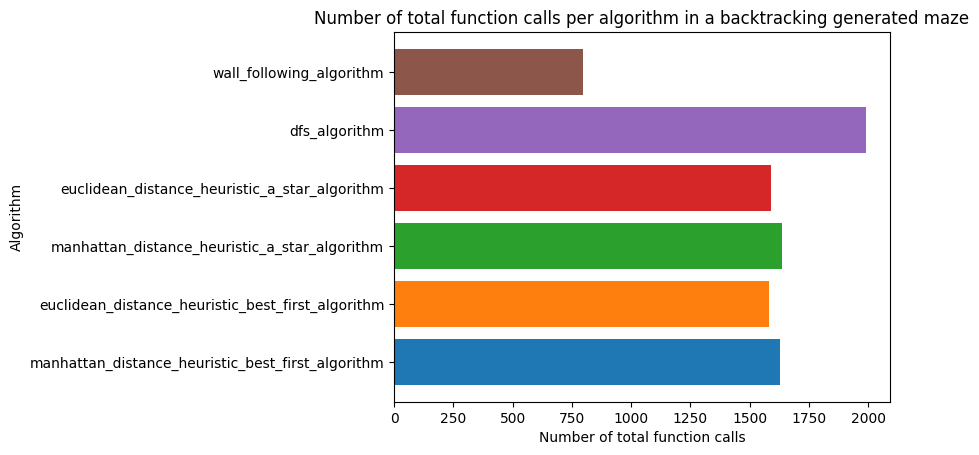

In [30]:
# Create plot
figure, axes = plt.subplots()

for key in algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY]:
    current_algorithm = algorithm_computation_stats[ALGORITHM_COMPUTATION_DICTIONARY_BACKTRACKING_GENERATED_MAZE_KEY][key]
    # draw time bars
    axes.barh(key, current_algorithm[ALGORITHM_COMPUTATION_DICTIONARY_TOTAL_FUNCTION_CALLS_NUMBER_KEY])

plt.xlabel('Number of total function calls')
plt.ylabel('Algorithm')
plt.title('Number of total function calls per algorithm in a backtracking generated maze')

# Show graph
plt.show()

This kind of analysis can be very significant when have a large amount of test data, like we will be doing in the next section.

## Comparative statistics

We will now test each algorithm a total of times equal to 80% of the area of the random generated maze. Each test will have one more obstacle placed in the maze than the previous one, starting with a maze with no obstacles and ending with one made only for the 80% by obstacles

In [55]:
TEST_MAZE_WIDTH = 10
TEST_MAZE_HEIGHT = 10
MAX_NUMBER_OF_MAZE_OBSTACLES = ((TEST_MAZE_WIDTH * TEST_MAZE_HEIGHT) * 80 // 100) + 1

TEST_RESULTS_ALGORITHM_NAME_KEY = "algorithm_name"
TEST_RESULTS_NUMBER_OF_MAZE_OBSTACLES_KEY = "number_of_maze_obstacles"
TEST_RESULTS_PATH_LENGTH_KEY = "path_length"
TEST_RESULTS_AGENT_STATES_NUMBER_KEY = "number_of_agent_states"
TEST_RESULTS_TOTAL_FUNCTION_CALLS_NUMBER_KEY = "number_of_total_function_calls"
TEST_RESULTS_EXECUTION_TIME_NUMBER_KEY = "execution_time"

TEST_RESULT_MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_NAME = "Manhattan Distance Heuristic Best First"
TEST_RESULT_EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_NAME = "Euclidean Distance Heuristic Best First"
TEST_RESULT_MANHATTAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_NAME = "Manhattan Distance Heuristic A*"
TEST_RESULT_EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_NAME = "Euclidean Distance Heuristic A*"
TEST_RESULT_DFS_ALGORITHM_NAME = "DFS"

test_results = []

def test_function(test_agent, maze_runner_function, heuristic, algorithm_name, test_results_index):
    with cProfile.Profile() as pr:
        if heuristic is not None:
            maze_path = maze_runner_function(heuristic)
        else:
            maze_path = maze_runner_function()
    
    stats = pstats.Stats(pr)

    # Get the total number of function calls
    total_function_calls = stats.total_calls

    # Get the total time in seconds
    total_time = stats.total_tt

    if test_results_index >= len(test_results):
        # index does not exist
        test_results.append([])
    
    test_results[test_results_index].append({
            TEST_RESULTS_ALGORITHM_NAME_KEY: algorithm_name,
            TEST_RESULTS_NUMBER_OF_MAZE_OBSTACLES_KEY: test_results_index,
            TEST_RESULTS_PATH_LENGTH_KEY: len(maze_path),
            TEST_RESULTS_AGENT_STATES_NUMBER_KEY: len(test_agent.states),
            TEST_RESULTS_TOTAL_FUNCTION_CALLS_NUMBER_KEY: total_function_calls,
            TEST_RESULTS_EXECUTION_TIME_NUMBER_KEY: total_time
        })
        
    

for number_of_obstacles in range(MAX_NUMBER_OF_MAZE_OBSTACLES):
    test_maze = randomized.create_maze(TEST_MAZE_WIDTH, TEST_MAZE_HEIGHT, number_of_obstacles)
    test_agent = Agent(test_maze)

    # Manhattan Distance Heuristic Best First
    test_function(test_agent, test_agent.best_first, manhattan.manhattan_distance_heuristic, TEST_RESULT_MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_NAME, number_of_obstacles)

    # Euclidean Distance Heuristic Best First
    test_function(test_agent, test_agent.best_first, euclidean.euclidean_distance_heuristic, TEST_RESULT_EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_NAME, number_of_obstacles)

    # Manhattan Distance Heuristic A*
    test_function(test_agent, test_agent.a_star, manhattan.manhattan_distance_heuristic, TEST_RESULT_MANHATTAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_NAME, number_of_obstacles)

    # Euclidean Distance Heuristic A*
    test_function(test_agent, test_agent.a_star, euclidean.euclidean_distance_heuristic, TEST_RESULT_EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_NAME, number_of_obstacles)

    # DFS
    test_function(test_agent, test_agent.dfs, None, TEST_RESULT_DFS_ALGORITHM_NAME, number_of_obstacles)

In order to plot these date, we create a function that handles this computation

In [56]:
def plot_algorithm_test_data_related_to_parameter(parameter_on_y_axis_key, y_axis_label, plot_title):
    y_axis = {
        TEST_RESULT_MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_NAME: [],
        TEST_RESULT_EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_NAME: [],
        TEST_RESULT_MANHATTAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_NAME: [],
        TEST_RESULT_EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_NAME: [],
        TEST_RESULT_DFS_ALGORITHM_NAME: []
    }
    x_axis_points = []

    for number_of_obstacles in range(MAX_NUMBER_OF_MAZE_OBSTACLES):
        x_axis_points.append(number_of_obstacles)
        
        for algorithm_test_data in test_results[number_of_obstacles]:
            y_axis[algorithm_test_data[TEST_RESULTS_ALGORITHM_NAME_KEY]].append(algorithm_test_data[parameter_on_y_axis_key])

    # Plot the algorithm functions
    plt.plot(x_axis_points, y_axis[TEST_RESULT_MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_NAME], label=TEST_RESULT_MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_NAME)
    plt.plot(x_axis_points, y_axis[TEST_RESULT_EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_NAME], label=TEST_RESULT_EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_ALGORITHM_NAME)
    plt.plot(x_axis_points, y_axis[TEST_RESULT_MANHATTAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_NAME], label=TEST_RESULT_MANHATTAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_NAME)
    plt.plot(x_axis_points, y_axis[TEST_RESULT_EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_NAME], label=TEST_RESULT_EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_ALGORITHM_NAME)
    plt.plot(x_axis_points, y_axis[TEST_RESULT_DFS_ALGORITHM_NAME], label=TEST_RESULT_DFS_ALGORITHM_NAME)

    # Add labels and title
    plt.xlabel('Number of obstacles in the maze')
    plt.ylabel(y_axis_label)
    plt.title(plot_title)

    # Add a legend
    plt.legend()

    plt.grid(True)
    plt.show()

Let's now compare the execution time of each algorithm over the increasing number of obstacles

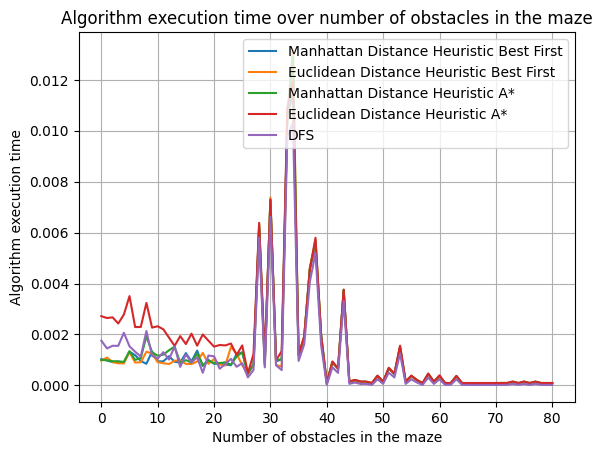

In [57]:
plot_algorithm_test_data_related_to_parameter(TEST_RESULTS_EXECUTION_TIME_NUMBER_KEY, 'Algorithm execution time', 'Algorithm execution time over number of obstacles in the maze')

then the length of the found paths

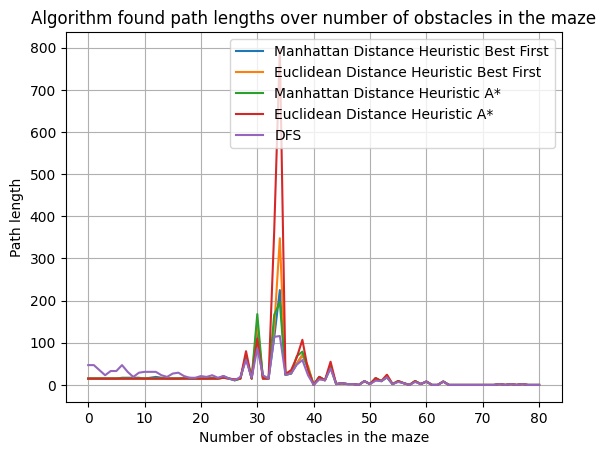

In [ ]:
plot_algorithm_test_data_related_to_parameter(TEST_RESULTS_PATH_LENGTH_KEY, 'Path length', 'Path lengths over number of obstacles in the maze')

number of agent states

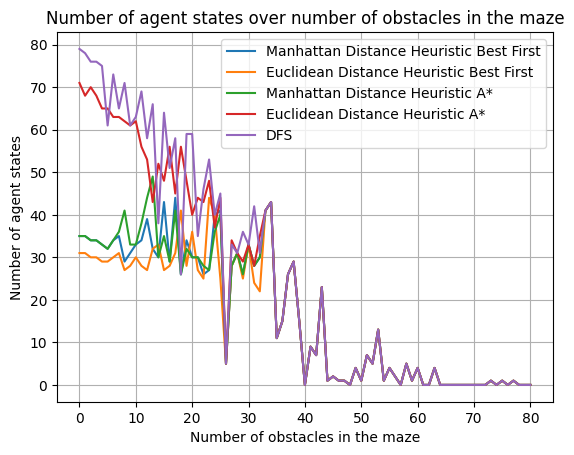

In [60]:
plot_algorithm_test_data_related_to_parameter(TEST_RESULTS_AGENT_STATES_NUMBER_KEY, 'Number of agent states', 'Number of agent states over number of obstacles in the maze')

and lastly, number of total function calls

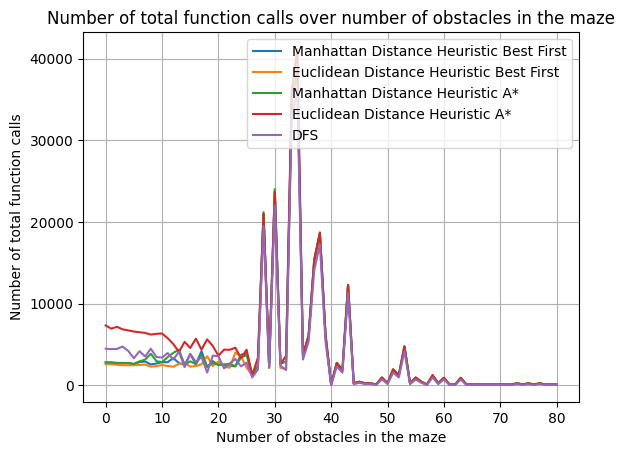

In [61]:
plot_algorithm_test_data_related_to_parameter(TEST_RESULTS_TOTAL_FUNCTION_CALLS_NUMBER_KEY, 'Number of total function calls', 'Number of total function calls over number of obstacles in the maze')

## Comparisons

Having seen three different algorithms for solving the generated 10x10 maze, we can tell that DFS and Best-first are not optimal because, while DFS often finds a solution quickly, it is not necessarily the shortest one, meanwhile the solution provided by the Best-first algorithm strongly depends on the quality of the heuristic function. A* on the other hand is optimal if the heurstic function is consistent (monotonically increasing).

Talking about time complexity, DFS has O(|V| + |E|) in the worst case, where |V| is the number of vertices and |E| is the number of edges, while Best-first varies based on the heuristic and the problem and A* is exponential in the worst case but oftern performs much ebtter inm pratice with a good heuristic.

Lastly, space complexity is also a factor to consider when comparing algorithms. On one hand we know that DFS has a space complexity of O(|V|) in the worst case, while on the other Best-first can vary widely, depending on the implementation and the heuristic function and A* is exponential in the worst case.

In conclusion we could say that:
- the DFS algorithm is good for finding a solution quickly, but may not be optimal, so it can be used when the search space is finite and the depth of the solution is known to be relatively small;
- Best-first can be faster than DFS, but less reliable, meaning that it could be used when a good heuristic function is available;
- A* is often the best choice for finding optimal solutions efficiently, so it can be used when a good heuristic function is available and the search space is large.